In [30]:
import pandas as pd
from io import BytesIO
from urllib.request import urlopen
from zipfile import ZipFile

URL = ('https://archive.ics.uci.edu/static/public/222/bank+marketing.zip')
outer = ZipFile(BytesIO(urlopen(URL).read()))
inner = ZipFile(BytesIO(outer.read('bank-additional.zip')))
df = pd.read_csv(inner.open('bank-additional/bank-additional.csv'), sep=';')
df.to_csv('bank.csv', sep=';', index=False)
print(df.shape) # (4119, 21)


(4119, 21)


In [31]:
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,30,blue-collar,married,basic.9y,no,yes,no,cellular,may,fri,...,2,999,0,nonexistent,-1.8,92.893,-46.2,1.313,5099.1,no
1,39,services,single,high.school,no,no,no,telephone,may,fri,...,4,999,0,nonexistent,1.1,93.994,-36.4,4.855,5191.0,no
2,25,services,married,high.school,no,yes,no,telephone,jun,wed,...,1,999,0,nonexistent,1.4,94.465,-41.8,4.962,5228.1,no
3,38,services,married,basic.9y,no,unknown,unknown,telephone,jun,fri,...,3,999,0,nonexistent,1.4,94.465,-41.8,4.959,5228.1,no
4,47,admin.,married,university.degree,no,yes,no,cellular,nov,mon,...,1,999,0,nonexistent,-0.1,93.200,-42.0,4.191,5195.8,no


In [32]:
df.isnull().sum()

age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y                 0
dtype: int64

In [33]:
df.describe()

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,4119.000000,4119.000000,4119.000000,4119.000000,4119.000000,4119.000000,4119.000000,4119.000000,4119.000000,4119.000000
mean,40.113620,256.788055,2.537266,960.422190,0.190337,0.084972,93.579704,-40.499102,3.621356,5166.481695
std,10.313362,254.703736,2.568159,191.922786,0.541788,1.563114,0.579349,4.594578,1.733591,73.667904
min,18.000000,0.000000,1.000000,0.000000,0.000000,-3.400000,92.201000,-50.800000,0.635000,4963.600000
25%,32.000000,103.000000,1.000000,999.000000,0.000000,-1.800000,93.075000,-42.700000,1.334000,5099.100000
50%,38.000000,181.000000,2.000000,999.000000,0.000000,1.100000,93.749000,-41.800000,4.857000,5191.000000
75%,47.000000,317.000000,3.000000,999.000000,0.000000,1.400000,93.994000,-36.400000,4.961000,5228.100000
max,88.000000,3643.000000,35.000000,999.000000,6.000000,1.400000,94.767000,-26.900000,5.045000,5228.100000


In [34]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4119 entries, 0 to 4118
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             4119 non-null   int64  
 1   job             4119 non-null   str    
 2   marital         4119 non-null   str    
 3   education       4119 non-null   str    
 4   default         4119 non-null   str    
 5   housing         4119 non-null   str    
 6   loan            4119 non-null   str    
 7   contact         4119 non-null   str    
 8   month           4119 non-null   str    
 9   day_of_week     4119 non-null   str    
 10  duration        4119 non-null   int64  
 11  campaign        4119 non-null   int64  
 12  pdays           4119 non-null   int64  
 13  previous        4119 non-null   int64  
 14  poutcome        4119 non-null   str    
 15  emp.var.rate    4119 non-null   float64
 16  cons.price.idx  4119 non-null   float64
 17  cons.conf.idx   4119 non-null   float64
 18 

In [35]:
df.duplicated().sum()

np.int64(0)

In [36]:
df.columns

Index(['age', 'job', 'marital', 'education', 'default', 'housing', 'loan',
       'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays',
       'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx',
       'cons.conf.idx', 'euribor3m', 'nr.employed', 'y'],
      dtype='str')

In [37]:
df = df.drop(columns=["duration"])

In [38]:
df.shape

(4119, 20)

In [39]:
df.describe()

,age,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,4119.000000,4119.000000,4119.000000,4119.000000,4119.000000,4119.000000,4119.000000,4119.000000,4119.000000
mean,40.113620,2.537266,960.422190,0.190337,0.084972,93.579704,-40.499102,3.621356,5166.481695
std,10.313362,2.568159,191.922786,0.541788,1.563114,0.579349,4.594578,1.733591,73.667904
min,18.000000,1.000000,0.000000,0.000000,-3.400000,92.201000,-50.800000,0.635000,4963.600000
25%,32.000000,1.000000,999.000000,0.000000,-1.800000,93.075000,-42.700000,1.334000,5099.100000
50%,38.000000,2.000000,999.000000,0.000000,1.100000,93.749000,-41.800000,4.857000,5191.000000
75%,47.000000,3.000000,999.000000,0.000000,1.400000,93.994000,-36.400000,4.961000,5228.100000
max,88.000000,35.000000,999.000000,6.000000,1.400000,94.767000,-26.900000,5.045000,5228.100000


In [40]:
df['y'] = df['y'].map({'yes': 1, 'no': 0})

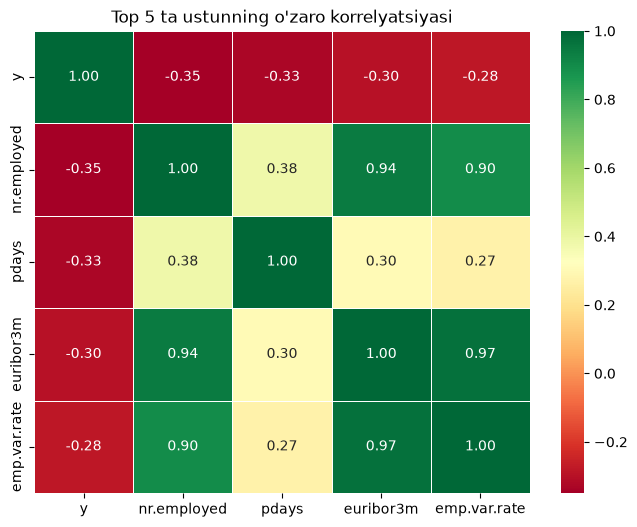

In [47]:
import matplotlib.pyplot as plt
import seaborn as sns

nums = df.select_dtypes(include='number')
top_cols = nums.corr()['y'].abs().sort_values(ascending=False).head().index

top_corr = nums[top_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(top_corr, annot=True, cmap='RdYlGn', fmt=".2f", linewidths=0.5)
plt.title("Top 5 ta ustunning o'zaro korrelyatsiyasi")
plt.show()

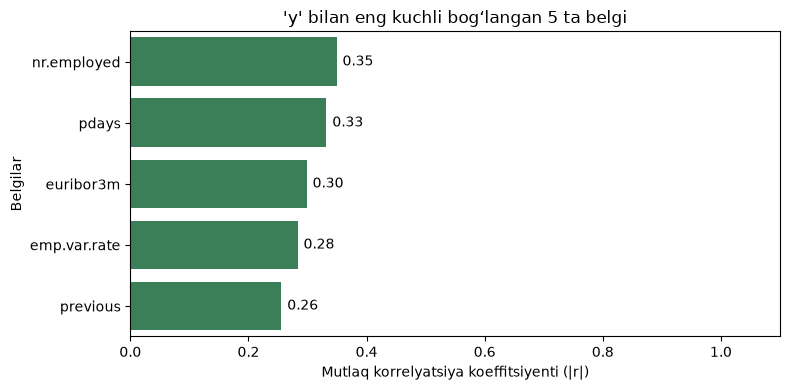

In [51]:
import matplotlib.pyplot as plt
import seaborn as sns

nums = df.select_dtypes(include="number")

# y sonli ustun bo‘lishi kerak
corr_series = (
    nums.corr()["y"].drop("y").dropna().abs().sort_values(ascending=False).head(5)
)

if corr_series.empty:
    print("Korrelyatsiyani hisoblash uchun yetarli ma’lumot yo‘q.")
else:
    plt.figure(figsize=(8, 4))

    sns.barplot(
        x=corr_series.values,
        y=corr_series.index,
        color="seagreen"
    )

    plt.title("'y' bilan eng kuchli bog‘langan 5 ta belgi")
    plt.xlabel("Mutlaq korrelyatsiya koeffitsiyenti (|r|)")
    plt.ylabel("Belgilar")
    plt.xlim(0, 1.1)

    for i, val in enumerate(corr_series.values):
        plt.text(
            val + 0.01, i, f"{val:.2f}",
            va="center", fontsize=10
        )

    plt.tight_layout()
    plt.show()

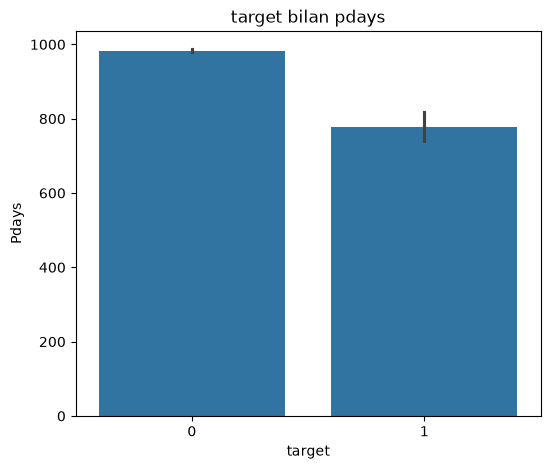

In [52]:
plt.figure(figsize=(6, 5))
sns.barplot(data=df, x='y', y='pdays')
plt.title('target bilan pdays')
plt.xlabel('target')
plt.ylabel('Pdays')
plt.show()

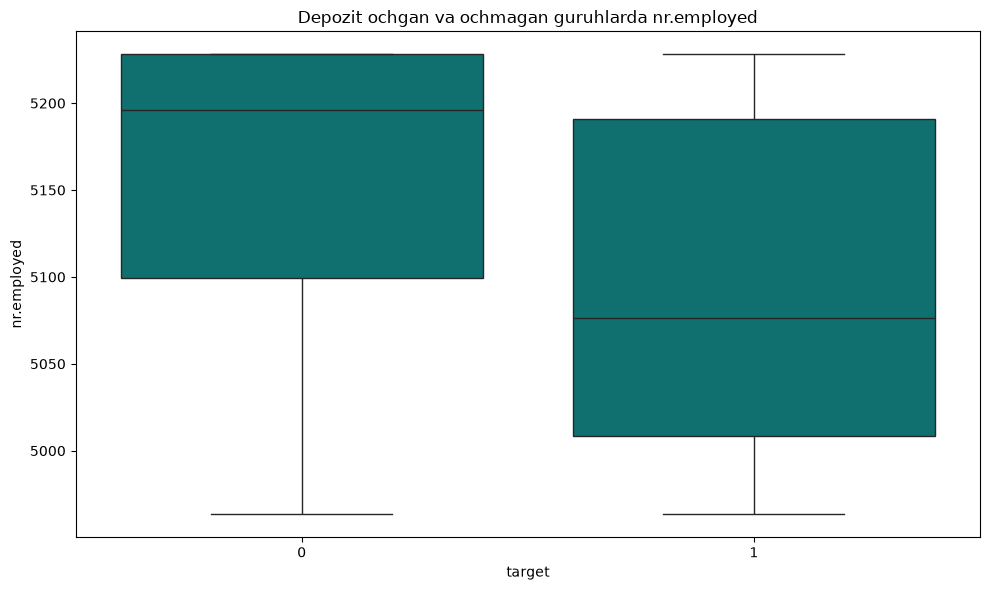

In [58]:
plt.figure(figsize=(10, 6))

sns.boxplot(data=df, x="y", y="nr.employed", color="teal")

plt.title("Depozit ochgan va ochmagan guruhlarda nr.employed")
plt.xlabel("target")
plt.ylabel("nr.employed")

plt.tight_layout()
plt.show()

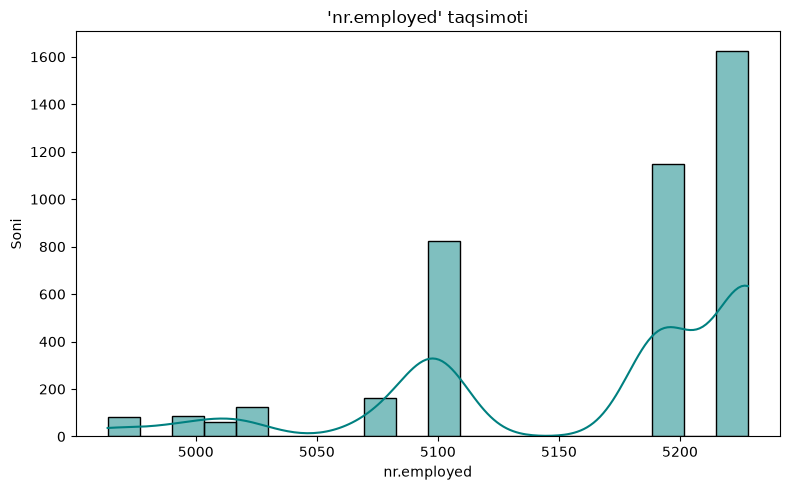

In [61]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="nr.employed", kde=True, color="teal", bins=20)
plt.title("'nr.employed' taqsimoti")
plt.xlabel("nr.employed")
plt.ylabel("Soni")
plt.tight_layout()
plt.show()

In [72]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier

pipeline = Pipeline([
	('sc', StandardScaler()),
	('model', RandomForestClassifier(n_estimators=100, random_state=42))
])
X = df.drop(columns=['y'])
y = df['y']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)


In [73]:
model = pipeline
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

ValueError: could not convert string to float: 'admin.'

In [2]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import train_test_split
X = df.drop(columns=['y'])
y = df['y']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

model = GradientBoostingClassifier(
	n_estimators=100,
	learning_rate=0.1,
	max_depth=3
)
model.fit(X_train, y_train)
print(model.score(X_train, y_train))
print(model.score(X_test, y_test))

NameError: name 'df' is not defined